# VGGNet — Very Deep Convolutional Networks for Large-Scale Image Recognition

**Citation:** Simonyan, K., & Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. In *International Conference on Learning Representations (ICLR 2015)*. arXiv:1409.1556.

**Registered names:** `vgg11`, `vgg13`, `vgg16`, `vgg19`, `vgg11_bn`, `vgg13_bn`, `vgg16_bn`, `vgg19_bn`

**Summary:** VGGNet's central finding: depth with small 3×3 filters outperforms shallower networks with larger kernels. Two stacked 3×3 convolutions have the same receptive field as one 5×5 but fewer parameters and more non-linearity.

---

| Model | Layers | Params | Top-1 |
|-------|--------|--------|-------|
| VGG-11 | 11 | 133M | 69.0% |
| VGG-16 | 16 | 138M | 71.5% |
| VGG-19 | 19 | 144M | 71.1% |
| VGG-16-BN | 16 | 138M | 73.4% |

> 📄 **Paper:** Simonyan & Zisserman (2015). Very Deep Convolutional Networks for Large-Scale Image Recognition. ICLR 2015.
> 🔗 **Link:** <https://arxiv.org/abs/1409.1556>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/vgg.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> B1["block 1: n × (conv 3×3 64 · [BN] · ReLU) · maxpool<br/>(B, 64, 112, 112)"]:::stage
  B1 --> B2["block 2: 128 ch<br/>(B, 128, 56, 56)"]:::stage --> B3["block 3: 256 ch<br/>(B, 256, 28, 28)"]:::stage
  B3 --> B4["block 4: 512 ch<br/>(B, 512, 14, 14)"]:::stage --> B5["block 5: 512 ch<br/>(B, 512, 7, 7)"]:::stage
  B5 --> FC["avgpool 7×7 · FC 4096 · FC 4096"]:::block --> OUT
  CFG["configs A/B/D/E = VGG-11/13/16/19<br/>convs per block (1,1,2,2,2) … (2,2,4,4,4)"]:::block -.-> B1
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Diagram

```
Input [B, 3, 224, 224]
       │
       ▼
╔══════════════════════╗
║ Stage 0             ║  1-2 × Conv(64, 3×3) + MaxPool  → [B, 64,  112, 112]
╚══════════════════════╝
       │
╔══════════════════════╗
║ Stage 1             ║  1-2 × Conv(128, 3×3) + MaxPool → [B, 128,  56,  56]
╚══════════════════════╝
       │
╔══════════════════════╗
║ Stage 2             ║  2-4 × Conv(256, 3×3) + MaxPool → [B, 256,  28,  28]
╚══════════════════════╝
       │
╔══════════════════════╗
║ Stage 3             ║  2-4 × Conv(512, 3×3) + MaxPool → [B, 512,  14,  14]
╚══════════════════════╝
       │
╔══════════════════════╗
║ Stage 4             ║  2-4 × Conv(512, 3×3) + MaxPool → [B, 512,   7,   7]
╚══════════════════════╝
       │
  AdaptiveAvgPool(7×7) → Flatten
  FC(25088→4096) → ReLU → Dropout
  FC(4096→4096)  → ReLU → Dropout
       │
       ▼
pooled_output [B, 4096]
```

**VGG-16 configuration:** `[64,64,M, 128,128,M, 256,256,256,M, 512,512,512,M, 512,512,512,M]`
where M = MaxPool.

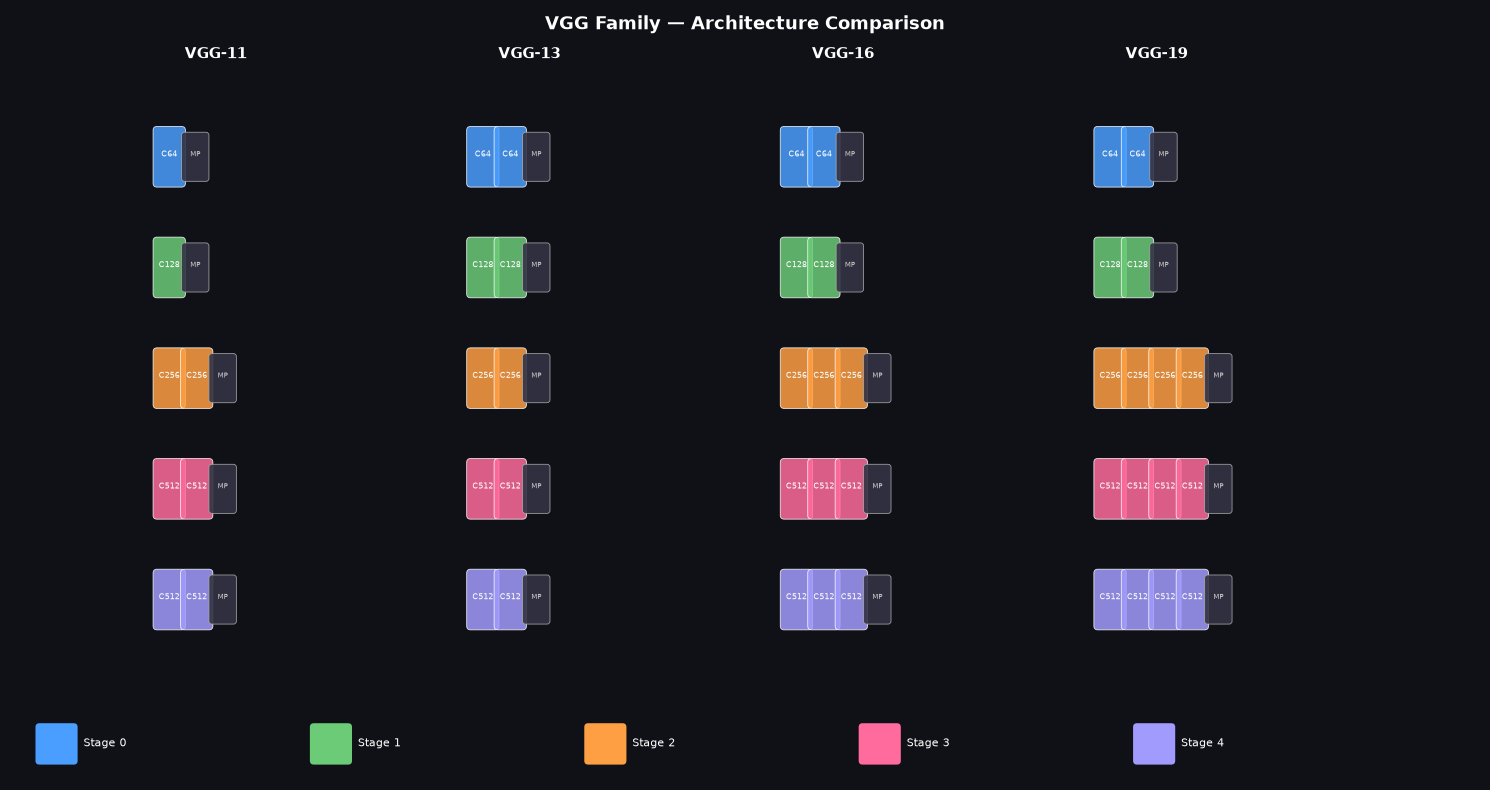

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 8))
fig.patch.set_facecolor('#0f1117')
ax.set_facecolor('#0f1117')
ax.set_xlim(0, 15); ax.set_ylim(0, 8); ax.axis('off')

# VGG block counts per variant
models = {
    'VGG-11': [1, 1, 2, 2, 2],
    'VGG-13': [2, 2, 2, 2, 2],
    'VGG-16': [2, 2, 3, 3, 3],
    'VGG-19': [2, 2, 4, 4, 4],
}
ch_labels = ['64', '128', '256', '512', '512']
colors = ['#4a9eff', '#6bcb77', '#ff9f43', '#ff6b9d', '#a29bfe']

# Draw comparison: each column = a model variant
for col, (name, blocks) in enumerate(models.items()):
    x_base = 1.5 + col * 3.2
    ax.text(x_base + 0.6, 7.5, name, ha='center', color='white', fontsize=11, fontweight='bold')
    y = 6.5
    for stage_i, (n, color) in enumerate(zip(blocks, colors)):
        for j in range(n):
            bx = x_base + j * 0.28
            box = FancyBboxPatch((bx, y - 0.3), 0.25, 0.55,
                                  boxstyle='round,pad=0.04', facecolor=color,
                                  edgecolor='white', linewidth=0.6, alpha=0.85)
            ax.add_patch(box)
            ax.text(bx + 0.125, y + 0.0, f'C{ch_labels[stage_i]}', ha='center',
                    va='center', fontsize=5.5, color='white')
        # MaxPool
        mp_x = x_base + n * 0.28
        ax.add_patch(FancyBboxPatch((mp_x, y - 0.25), 0.22, 0.45,
                                     boxstyle='round,pad=0.03', facecolor='#333344',
                                     edgecolor='#aaaaaa', linewidth=0.6, alpha=0.9))
        ax.text(mp_x + 0.11, y, 'MP', ha='center', va='center', fontsize=5, color='#cccccc')
        y -= 1.15

ax.text(7.5, 7.8, 'VGG Family — Architecture Comparison', ha='center',
        color='white', fontsize=13, fontweight='bold')

# Legend
for i, (name, color) in enumerate(zip([f'Stage {s}' for s in range(5)], colors)):
    ax.add_patch(FancyBboxPatch((0.3 + i * 2.8, 0.2), 0.35, 0.35,
                                 boxstyle='round,pad=0.04', facecolor=color, edgecolor='none'))
    ax.text(0.75 + i * 2.8, 0.38, name, color='white', fontsize=8, va='center')

plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. Small Filters — The 3×3 Principle
VGGNet's central argument: two stacked 3×3 convolutions are equivalent to one 5×5 conv in terms of receptive field:
$$r_2 \times r_2 \text{ via stack of 2: } 3+(3-1)=5$$
Three stacked 3×3 convolutions = one 7×7 conv. But the stacked version has:
- **Fewer parameters:** $3 \times (3^2 C^2) = 27C^2$ vs $7^2 C^2 = 49C^2$
- **More non-linearity:** 3 ReLU layers vs 1

### 2. Monotonic Channel Doubling
Each stage doubles channels (64→128→256→512), capturing progressively more abstract features.

### 3. Homogeneous Design
No special modules or hyperparameters per stage — the same pattern (3×3 Conv + ReLU) repeated. This simplicity made VGGNet very influential as a transfer learning backbone.

### 4. Large FC Head
The 3-layer FC head (4096→4096→1000) holds most of the parameters (102M/138M). Later work (GAP + small head) reduced this dramatically.

### BatchNorm Variants
Adding BatchNorm after each Conv (not in the original paper) significantly improves training stability and accuracy:
$$\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \quad y = \gamma \hat{x} + \beta$$

## Code Walkthrough

Implemented in `hale_core/nn/vision/cnn/vgg.py`.

**Configuration-driven stage builder:**
```python
_CFGS = {
    'vgg16': [64, 64, 'M', 128, 128, 'M', 256, 256, 256, 'M', 512, 512, 512, 'M', 512, 512, 512, 'M'],
}

def _make_vgg_stages(cfg, batch_norm, in_chans=3):
    stages, layers, in_ch = [], [], in_chans
    for v in cfg:
        if v == 'M':
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            stages.append(nn.Sequential(*layers))
            layers = []
        else:
            layers.append(nn.Conv2d(in_ch, v, kernel_size=3, padding=1))
            if batch_norm: layers.append(nn.BatchNorm2d(v))
            layers.append(nn.ReLU(inplace=True))
            in_ch = v
    return stages
```

All 8 variants (vgg11/13/16/19, ±BN) share one `VGG` class. The `_bn` variants pass `batch_norm=True`.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/vgg.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/vgg.py</code></summary>

```text
VGGNet Vision Backbones
=======================

Implements the VGG family (Simonyan & Zisserman, ICLR 2015).
VGG demonstrated that depth with small 3×3 convolutions outperforms shallower
networks with larger kernels — a key insight that shaped CNN design for years.

Architecture
------------
All VGG variants share the same pattern: sequential conv-pool stages followed
by a 3-layer FC classifier. The configs differ only in how many conv layers
appear per stage:

  Stage 0: 1–2 × Conv(64) + MaxPool   → H/2
  Stage 1: 1–2 × Conv(128) + MaxPool  → H/4
  Stage 2: 2–4 × Conv(256) + MaxPool  → H/8
  Stage 3: 2–4 × Conv(512) + MaxPool  → H/16
  Stage 4: 2–4 × Conv(512) + MaxPool  → H/32
  Classifier: AdaptiveAvgPool(7,7) → FC(4096) → FC(4096)

_bn variants add BatchNorm2d after every Conv, which wasn't in the original
paper but dramatically improves training stability and final accuracy.

Weight initialisation:
  Convolutions: Kaiming normal.
  Linear layers: truncated normal (std=0.01).

Registered names
----------------
  vgg11, vgg13, vgg16, vgg19           — without BatchNorm
  vgg11_bn, vgg13_bn, vgg16_bn, vgg19_bn — with BatchNorm

Citation
--------
  Simonyan, K., & Zisserman, A. (2015). Very Deep Convolutional Networks for
  Large-Scale Image Recognition. ICLR 2015. arXiv:1409.1556.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/vgg.py`, definition by definition

In [5]:
# ── VGG configuration table ───────────────────────────────────────────────────
# Each list entry is either an int (out_channels for a Conv3×3) or 'M' (MaxPool).
# Five MaxPools divide the backbone into 5 stages.
_CFGS: dict[str, list[int | str]] = {
    "vgg11": [64, "M", 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"],
    "vgg13": [64, 64, "M", 128, 128, "M", 256, 256, "M", 512, 512, "M", 512, 512, "M"],
    "vgg16": [64, 64, "M", 128, 128, "M", 256, 256, 256, "M", 512, 512, 512, "M", 512, 512, 512, "M"],
    "vgg19": [64, 64, "M", 128, 128, "M", 256, 256, 256, 256, "M", 512, 512, 512, 512, "M", 512, 512, 512, 512, "M"],
}

In [6]:
def _make_vgg_stages(
    cfg: list[int | str],
    batch_norm: bool,
    in_chans: int = 3,
) -> list[nn.Sequential]:
    """Parse a VGG config into 5 nn.Sequential stage modules.

    Each MaxPool ('M') marks a stage boundary.  We split the config at each
    'M' so that stage.forward() handles one spatial scale.

    Returns list of 5 nn.Sequential modules, one per stage (5 MaxPools total).
    """
    stages: list[nn.Sequential] = []
    layers: list[nn.Module] = []
    in_ch = in_chans

    for v in cfg:
        if v == "M":
            layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
            stages.append(nn.Sequential(*layers))
            layers = []
        else:
            assert isinstance(v, int)
            layers.append(nn.Conv2d(in_ch, v, kernel_size=3, padding=1))
            if batch_norm:
                layers.append(nn.BatchNorm2d(v))
            layers.append(nn.ReLU(inplace=True))
            in_ch = v

    # Remaining layers after last MaxPool (shouldn't happen with standard cfgs,
    # but guard against custom configs)
    if layers:
        stages.append(nn.Sequential(*layers))

    return stages

**`VGG`** - Generic VGG backbone.

In [7]:
class VGG(BaseVisionBackbone):
    """Generic VGG backbone.

    Args:
        cfg_name:   One of "vgg11", "vgg13", "vgg16", "vgg19".
        batch_norm: Whether to add BatchNorm after each Conv.
        img_size:   Expected input resolution (any size works).
        in_chans:   Input channels.
        drop_rate:  Dropout probability in the FC classifier.
    """

    embed_dim    = 4096
    feature_dims = [64, 128, 256, 512, 512]

    def __init__(
        self,
        cfg_name:   str,
        batch_norm: bool  = False,
        img_size:   int   = 224,
        in_chans:   int   = 3,
        drop_rate:  float = 0.5,
        **kwargs,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate)

        cfg = _CFGS[cfg_name]
        stage_list = _make_vgg_stages(cfg, batch_norm, in_chans=in_chans)

        # Each VGG config has exactly 5 MaxPool separators → 5 stages
        assert len(stage_list) == 5, f"Expected 5 stages, got {len(stage_list)}"
        self.stage0, self.stage1, self.stage2, self.stage3, self.stage4 = stage_list
        self._stage_list = stage_list

        # AdaptiveAvgPool → 7×7 normalises any input resolution for the FC head
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))

        p = drop_rate if drop_rate > 0.0 else 0.0
        self.classifier = nn.Sequential(
            nn.Linear(512 * 7 * 7, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=p),
            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=p),
        )

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.01)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        s0 = self.stage0(x)   # [B, 64,  H/2,  W/2]
        s1 = self.stage1(s0)  # [B, 128, H/4,  W/4]
        s2 = self.stage2(s1)  # [B, 256, H/8,  W/8]
        s3 = self.stage3(s2)  # [B, 512, H/16, W/16]
        s4 = self.stage4(s3)  # [B, 512, H/32, W/32]

        pooled = self.avgpool(s4).flatten(1)    # [B, 512*7*7]
        pooled = self.classifier(pooled)        # [B, 4096]

        all_maps = [s0, s1, s2, s3, s4]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        if stage < 0 or stage > 4:
            raise ValueError(f"stage must be in [0, 4], got {stage}")
        for i in range(stage + 1):
            for p in self._stage_list[i].parameters():
                p.requires_grad_(False)

**`VGG11`**

In [8]:
@register_vision_backbone("vgg11")
class VGG11(VGG):
    arch_name = "vgg11"
    def __init__(self, **kwargs): super().__init__("vgg11", batch_norm=False, **kwargs)

**`VGG13`**

In [9]:
@register_vision_backbone("vgg13")
class VGG13(VGG):
    arch_name = "vgg13"
    def __init__(self, **kwargs): super().__init__("vgg13", batch_norm=False, **kwargs)

**`VGG16`**

In [10]:
@register_vision_backbone("vgg16")
class VGG16(VGG):
    arch_name = "vgg16"
    def __init__(self, **kwargs): super().__init__("vgg16", batch_norm=False, **kwargs)

**`VGG19`**

In [11]:
@register_vision_backbone("vgg19")
class VGG19(VGG):
    arch_name = "vgg19"
    def __init__(self, **kwargs): super().__init__("vgg19", batch_norm=False, **kwargs)

**`VGG11BN`**

In [12]:
@register_vision_backbone("vgg11_bn")
class VGG11BN(VGG):
    arch_name = "vgg11_bn"
    def __init__(self, **kwargs): super().__init__("vgg11", batch_norm=True, **kwargs)

**`VGG13BN`**

In [13]:
@register_vision_backbone("vgg13_bn")
class VGG13BN(VGG):
    arch_name = "vgg13_bn"
    def __init__(self, **kwargs): super().__init__("vgg13", batch_norm=True, **kwargs)

**`VGG16BN`**

In [14]:
@register_vision_backbone("vgg16_bn")
class VGG16BN(VGG):
    arch_name = "vgg16_bn"
    def __init__(self, **kwargs): super().__init__("vgg16", batch_norm=True, **kwargs)

**`VGG19BN`**

In [15]:
@register_vision_backbone("vgg19_bn")
class VGG19BN(VGG):
    arch_name = "vgg19_bn"
    def __init__(self, **kwargs): super().__init__("vgg19", batch_norm=True, **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [16]:
DEMOS = {"vgg11": 132.9, "vgg16": 138.4}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['vgg11', 'vgg11_bn', 'vgg13', 'vgg13_bn', 'vgg16', 'vgg16_bn', 'vgg19', 'vgg19_bn']



vgg11  (VGG11)
  pooled_output : (2, 4096)   embed_dim = 4096
  feature_map 0: (2, 64, 112, 112)   stride 2
  feature_map 1: (2, 128, 56, 56)   stride 4
  feature_map 2: (2, 256, 28, 28)   stride 8
  feature_map 3: (2, 512, 14, 14)   stride 16
  feature_map 4: (2, 512, 7, 7)   stride 32



vgg16  (VGG16)
  pooled_output : (2, 4096)   embed_dim = 4096
  feature_map 0: (2, 64, 112, 112)   stride 2
  feature_map 1: (2, 128, 56, 56)   stride 4
  feature_map 2: (2, 256, 28, 28)   stride 8
  feature_map 3: (2, 512, 14, 14)   stride 16
  feature_map 4: (2, 512, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [17]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
vgg11                   128.77M    132.86M   132.9M    1.00  ✅
vgg16                   134.26M    138.36M   138.4M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [18]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

vgg11: loss 0.6936 | 20/20 parameter tensors receive a finite gradient


vgg16: loss 0.5118 | 30/30 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [19]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

vgg11: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


vgg16: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

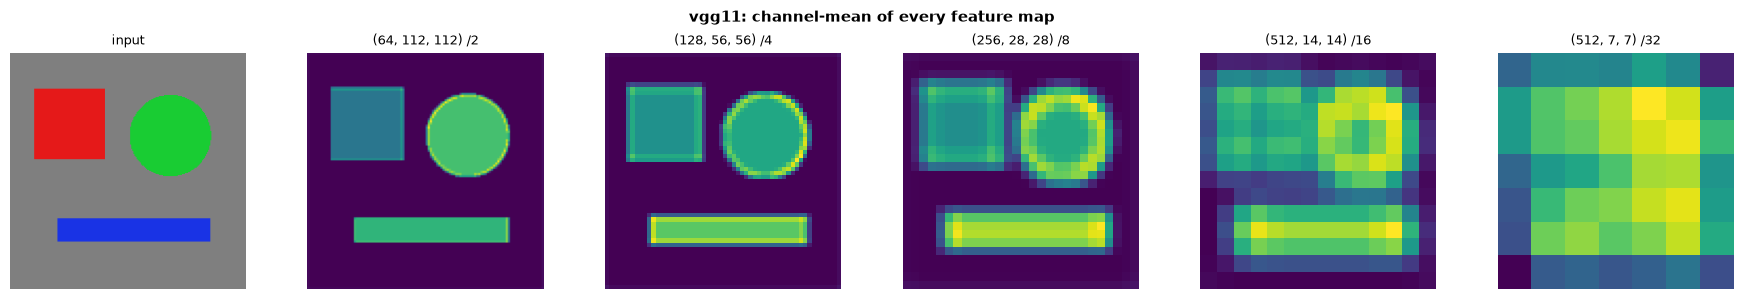

In [20]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [21]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [22]:
import torch
import sys


for name in ['vgg11', 'vgg16', 'vgg19', 'vgg16_bn']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        out = bb(x)
    fmap_shapes = [tuple(f.shape) for f in out.feature_maps]
    print(f'{name:12s} pooled={tuple(out.pooled_output.shape)} '
          f'params={bb.num_parameters()/1e6:.1f}M')
    print(f'             feature_maps: {fmap_shapes}')

vgg11        pooled=(1, 4096) params=128.8M
             feature_maps: [(1, 64, 112, 112), (1, 128, 56, 56), (1, 256, 28, 28), (1, 512, 14, 14), (1, 512, 7, 7)]


vgg16        pooled=(1, 4096) params=134.3M
             feature_maps: [(1, 64, 112, 112), (1, 128, 56, 56), (1, 256, 28, 28), (1, 512, 14, 14), (1, 512, 7, 7)]


vgg19        pooled=(1, 4096) params=139.6M
             feature_maps: [(1, 64, 112, 112), (1, 128, 56, 56), (1, 256, 28, 28), (1, 512, 14, 14), (1, 512, 7, 7)]


vgg16_bn     pooled=(1, 4096) params=134.3M
             feature_maps: [(1, 64, 112, 112), (1, 128, 56, 56), (1, 256, 28, 28), (1, 512, 14, 14), (1, 512, 7, 7)]


## References

| Paper | Venue | Key Contribution |
|-------|-------|------------------|
| Simonyan & Zisserman (2015). Very Deep CNNs. | ICLR 2015 | VGGNet — small filter depth principle |
| Krizhevsky et al. (2012). ImageNet Classification. | NeurIPS 2012 | AlexNet — predecessor, large filters |
| He et al. (2016). Deep Residual Learning. | CVPR 2016 | ResNet — skip connections supersede VGG |
| Ioffe & Szegedy (2015). Batch Normalisation. | ICML 2015 | BN — enables _bn variants |
| Zeiler & Fergus (2014). Visualising CNNs. | ECCV 2014 | Analysis of why depth helps |

**Full Citation:**
> Simonyan, K., & Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. In *International Conference on Learning Representations (ICLR 2015)*. arXiv:1409.1556.